# 08 · Machine learning (1/2): weak labels and classifiers for $B^\pm\to K^\pm K^+K^-$

**What this notebook does.** The mass fits separate signal from background through the *shape of the mass spectrum*.
Here classifiers do it from the *other* variables of the candidates. There are no true labels, so they are trained on
**weak labels** built from the mass (signal-like under the peak, background-like in the far sidebands), never on the mass
itself. Six classifiers are compared and studied: regularisation (Ridge, Lasso), bias–variance, calibration,
uncertainty estimators and hyperparameter search.

| § | Content | Report section |
|---|---|---|
| 1 | Data, mass fit for $\mu,\sigma$, weak labels, train/validation/test split | Weak labels and classifiers |
| 2 | Six classifiers: cross-validated and test AUC, ROC, feature importance | Weak labels and classifiers |
| 3 | Ridge/Lasso, bias–variance, calibration | Regularization, bias-variance, uncertainty |
| 4 | Uncertainty of the score: forest spread, MC dropout, deep ensemble | Uncertainty (add.) |
| 5 | Hyperparameter search, winner's curse [EXTRA] | Add.: hyperparameter optimization |

The use of the classifier in the measurement is in `09_ML_measurement`.

**Scale.** A guided tour of the method, not the production run: replicas, toy experiments and chains are fewer than in
the report, so numbers can differ slightly from it; next to every result the notebook prints the value of the report
(**report:**). The notebook is self-contained and saves its figures in `figures/` and its numbers in `results/`.
Parts beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Setup

In [1]:
import os, time, warnings, copy, json
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.stats import norm, chi2, spearmanr
from iminuit import Minuit, cost
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, accuracy_score, silhouette_score, adjusted_rand_score
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
import tensorflow as tf
from tensorflow import keras

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
SEED = 42
np.random.seed(SEED)

# figures and numerical results are saved next to the notebook
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    """Save the current figure in figures/ and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data and weak labels

### 1.1 Data
Same preselection and window as in the other notebooks, now with the *features* for the classifiers: for each
of the three tracks the momentum components, the two PID likelihoods and the impact-parameter $\chi^2$ (18 features),
plus two variables of the $B$ candidate (flight distance, vertex $\chi^2$): **20 features, the mass is not one of them**.
We keep a looser PID sample (`ProbK` > 0.3) for the study of §8 and select the nominal one from it.

In [2]:
tracks = (1, 2, 3)                                     # the three final-state hadrons
# the 20 features: for each track momentum components, PID likelihoods and impact-parameter chi2 (18) + 2 of the B
FEATURES = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "IPChi2")] + ["B_FlightDistance", "B_VertexChi2"]
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge", "IPChi2")]
branches += ["B_FlightDistance", "B_VertexChi2"]
frames = []
for pol in ("Down", "Up"):                             # one file per magnet polarity
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)
# loose preselection: ProbK > 0.3 (the nominal one is ProbK > 0.5, applied below)
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.3) & (df[f"H{i}_ProbPi"] < 0.5) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks, kaon mass hypothesis."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge                     # charge of the B
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)      # weakest kaon likelihood of the candidate
d = d[(np.abs(d.q) == 1) & (d.m > LO) & (d.m < HI)].reset_index(drop=True)
data = d[d.min_probk > 0.5].reset_index(drop=True)                   # nominal sample (ProbK > 0.5 on all tracks)
print(f"candidates in the window: nominal {len(data)} (report 19731),  looser ProbK > 0.3: {len(d)} (report 33328)")

candidates in the window: nominal 19731 (report 19731),  looser ProbK > 0.3: 33328 (report 33328)


### 1.2 Mass fit: $\mu$ and $\sigma$ for the labels

A compact version of the nominal fit of notebook 01 (simultaneous fit of $B^+$ and $B^-$, Gaussian signal,
double-exponential background per charge). We need it now for $\mu$ and $\sigma$, and in §6 and §8 to refit the
selected samples. Model and fit are written exactly as in notebook 01.

In [3]:
# --- the nominal mass model and fit, exactly as in notebook 01 (here to obtain mu and sigma, and to refit later)
def gauss_pdf(m, mu, sigma):
    """Gaussian normalised on the fit window [LO, HI]."""
    return norm.pdf(m, mu, sigma) / (norm.cdf(HI, mu, sigma) - norm.cdf(LO, mu, sigma))
def exp_pdf(m, lam):
    """Exponential normalised on the window."""
    return lam * np.exp(-lam * (m - LO)) / (1 - np.exp(-lam * (HI - LO)))
def bkg_pdf(m, lam1, lam2, f):
    """Background: two exponentials, weight f on the steep one."""
    return f * exp_pdf(m, lam1) + (1 - f) * exp_pdf(m, lam2)

# one extended model per charge; N_s, A, mu, sigma are shared by the two (same name)
def model_pos(m, N_s, A, mu, sigma, N_b_pos, lam1_pos, lam2_pos, f_pos):
    n_sig = N_s * (1 - A) / 2                                          # B+ : (1 - A) / 2
    return n_sig + N_b_pos, n_sig * gauss_pdf(m, mu, sigma) + N_b_pos * bkg_pdf(m, lam1_pos, lam2_pos, f_pos)
def model_neg(m, N_s, A, mu, sigma, N_b_neg, lam1_neg, lam2_neg, f_neg):
    n_sig = N_s * (1 + A) / 2                                          # B- : (1 + A) / 2
    return n_sig + N_b_neg, n_sig * gauss_pdf(m, mu, sigma) + N_b_neg * bkg_pdf(m, lam1_neg, lam2_neg, f_neg)

def fit_asymmetry(s):
    """Nominal simultaneous fit on a sample s (columns m, q). Returns the Minuit object (A, errors, chi2 via fval)."""
    mp, mn = s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy()
    nll = cost.ExtendedUnbinnedNLL(mp, model_pos) + cost.ExtendedUnbinnedNLL(mn, model_neg)     # sum of the two charges
    f = Minuit(nll, N_s=0.78 * len(s), A=-0.04, mu=5284.0, sigma=18.0,
               N_b_pos=0.22 * len(mp), lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15,
               N_b_neg=0.22 * len(mn), lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)
    f.limits["A"] = (-1, 1); f.limits["mu"] = (5260, 5310); f.limits["sigma"] = (3, 40)
    f.limits["N_s"] = (0, 2 * len(s))
    for side in ("pos", "neg"):
        f.limits[f"N_b_{side}"] = (0, 2 * len(s))
        f.limits[f"lam1_{side}"] = (1e-5, 0.1); f.limits[f"lam2_{side}"] = (1e-5, 0.1); f.limits[f"f_{side}"] = (0, 1)
    f.migrad(); f.hesse()
    return f

fit_all = fit_asymmetry(data)
MU, SIGMA = fit_all.values["mu"], fit_all.values["sigma"]              # peak position and resolution
A_full, dA_full = fit_all.values["A"], fit_all.errors["A"]             # result on the full sample, for comparison
print(f"mu = {MU:.2f} MeV, sigma = {SIGMA:.2f} MeV;  A_raw = {A_full:+.4f} +- {dA_full:.4f}   (report: 5284.39, 18.00, -0.0441 +- 0.0085)")

mu = 5284.38 MeV, sigma = 18.00 MeV;  A_raw = -0.0441 +- 0.0085   (report: 5284.39, 18.00, -0.0441 +- 0.0085)


### 1.3 Weak labels

No candidate carries a true label. We build **weak labels** from the mass spectrum, following the
*classification without labels* idea (CWoLa): a classifier that separates two samples with *different signal
fractions* — here the window under the peak (mostly signal) and the far sidebands (mostly background) — is, by the
Neyman–Pearson lemma, also the optimal signal/background classifier, **provided the features carry no information on
the mass**. This is why the mass is not a feature.

* signal-like: $|m-\mu|<2\sigma$; background-like: $m\in[5150,\mu-4\sigma]\cup[\mu+4\sigma,5600]$ MeV;
* the gaps $2$–$4\sigma$ and the region below 5150 MeV (partially reconstructed decays, not representative of the
  background under the peak) stay unlabelled.

signal-like 15132, background-like 1939   (report: 15130 and 1940; ratio 0.128)


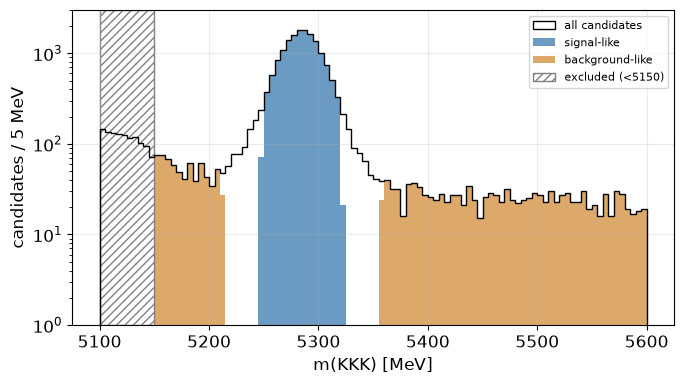

In [4]:
m = data.m.to_numpy()
is_sig = np.abs(m - MU) < 2 * SIGMA                                    # signal-like: within 2 sigma of the peak
# background-like: far sidebands (beyond 4 sigma), above 5150 MeV (below, partially reconstructed decays)
is_bkg = ((m >= 5150) & (m < MU - 4 * SIGMA)) | ((m > MU + 4 * SIGMA) & (m <= HI))
labeled = data[is_sig | is_bkg].copy()                                 # the 2-4 sigma gap stays unlabelled
labeled["y"] = is_sig[is_sig | is_bkg].astype(int)                     # weak label: 1 = signal-like, 0 = background-like
print(f"signal-like {int(labeled.y.sum())}, background-like {int((labeled.y == 0).sum())}   (report: 15130 and 1940; ratio 0.128)")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(LO, HI + 1, 5)
ax.hist(m, bins, histtype="step", color="k", label="all candidates")
ax.hist(m[is_sig], bins, color=C["signal"], alpha=0.8, label="signal-like")
ax.hist(m[is_bkg], bins, color="#d9a05b", alpha=0.9, label="background-like")
ax.axvspan(LO, 5150, facecolor="none", hatch="////", edgecolor="0.5", label="excluded (<5150)")
ax.set(yscale="log", xlabel="m(KKK) [MeV]", ylabel="candidates / 5 MeV", ylim=(1, 3e3)); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("08_weak_labels")

**Train / validation / test split** (stratified 60/20/20) with the standardisation fitted on the training set only.
The classes are imbalanced (0.128): every model uses `balanced` class weights $w_c=N/(2N_c)$.

In [5]:
X, y = labeled[FEATURES].to_numpy(), labeled.y.to_numpy()               # features (the mass is NOT among them) and labels
# stratified split: the class proportions are the same in training, validation and test
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
scaler = StandardScaler().fit(X_train)                                  # standardisation from the training set only
Xs_train, Xs_val, Xs_test = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
w = {c: len(y_train) / (2 * np.sum(y_train == c)) for c in (0, 1)}      # balanced class weights w_c = N / (2 N_c)
sw_train = np.where(y_train == 1, w[1], w[0])                           # the same as a weight per training sample
print(f"train/val/test = {len(y_train)}/{len(y_val)}/{len(y_test)};  class weights: {w[0]:.2f} (background), {w[1]:.2f} (signal)")

train/val/test = 10242/3414/3415;  class weights: 4.40 (background), 0.56 (signal)


In [6]:
# the weak labels and the split, saved
pd.DataFrame({"n_window": [len(data)], "n_signal_like": [int(labeled.y.sum())], "n_background_like": [int((labeled.y == 0).sum())],
              "n_train": [len(y_train)], "n_val": [len(y_val)], "n_test": [len(y_test)], "mu": [MU], "sigma": [SIGMA]}).to_csv(
    "results/08_labels_and_split.csv", index=False)

## 2 · Six classifiers

Logistic regression with $L_2$ (Ridge) and $L_1$ (Lasso) penalty, a decision tree, a random forest, gradient boosting
and a feed-forward neural network (FFNN). The ranking metric is the **AUC** (area under the ROC curve): the reference
model is chosen on the 5-fold **cross-validated** AUC of the training set, not on the test set; the test AUC is quoted
with a bootstrap uncertainty.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)       # 5-fold cross-validation on the training set
# name -> (model, does it take the standardised features?); trees do not need standardisation
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), True),           # L2 (Ridge)
    "Logistic Regression (L1)": (LogisticRegression(penalty="l1", solver="liblinear", C=0.1, class_weight="balanced", max_iter=2000), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight="balanced", random_state=SEED), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                             random_state=SEED, n_jobs=-1), False),
    "Gradient Boosting": (GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED), False),
}
cv_auc, fitted = {}, {}
for name, (mdl, scaled) in models.items():
    Xtr = Xs_train if scaled else X_train
    if name == "Gradient Boosting":
        # gradient boosting takes class weights through sample_weight: cross-validate by hand
        sc = np.array([roc_auc_score(y_train[te], GradientBoostingClassifier(**mdl.get_params()).fit(
            Xtr[tr], y_train[tr], sample_weight=sw_train[tr]).predict_proba(Xtr[te])[:, 1]) for tr, te in cv.split(Xtr, y_train)])
        mdl.fit(Xtr, y_train, sample_weight=sw_train)
    else:
        sc = cross_val_score(mdl, Xtr, y_train, cv=cv, scoring="roc_auc")     # AUC in each of the 5 folds
        mdl.fit(Xtr, y_train)
    cv_auc[name] = (sc.mean(), sc.std()); fitted[name] = (mdl, scaled)
    print(f"{name:26s} CV AUC = {sc.mean():.4f} +- {sc.std():.4f}")

Logistic Regression        CV AUC = 0.7802 +- 0.0072


Logistic Regression (L1)   CV AUC = 0.7804 +- 0.0073


Decision Tree              CV AUC = 0.8241 +- 0.0111


Random Forest              CV AUC = 0.8697 +- 0.0139


Gradient Boosting          CV AUC = 0.8698 +- 0.0144


**Reading the result.** The tree ensembles (and, below, the neural network) clearly beat the linear models and the single tree; between forest and boosting the difference is smaller than the uncertainty of the test AUC, so the choice of the reference (the one with the best cross-validated AUC) is not critical.

**FFNN.** Fully connected network, ReLU activations, dropout, sigmoid output, binary cross-entropy, Adam,
early stopping on the validation AUC, class weights.

model                       test AUC  (boot sd)   Brier


Logistic Regression           0.7773     0.0128   0.191


Logistic Regression (L1)      0.7767     0.0131   0.192


Decision Tree                 0.8247     0.0127   0.132


Random Forest                 0.8660     0.0119   0.120


Gradient Boosting             0.8721     0.0112   0.112


FFNN                          0.8582     0.0114   0.139
report: tree ensembles and FFNN 0.857-0.864 (indistinguishable, test-set uncertainty 0.012), linear models ~0.77, single tree ~0.82; reference = gradient boosting


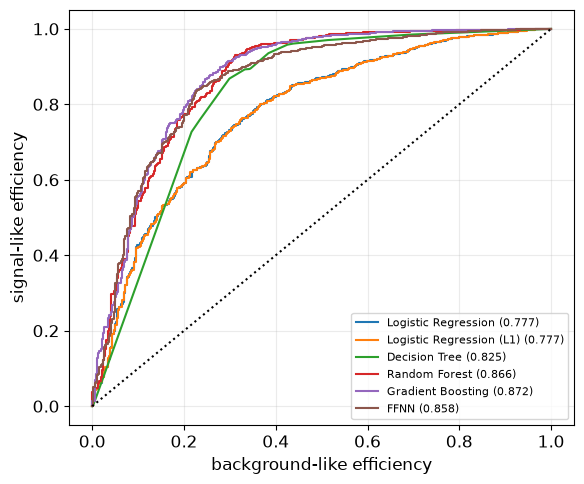

In [8]:
def build_ffnn(layers=(32, 16), dropout=0.2, lr=1e-3, seed=0):
    """Fully connected network: [Dense(ReLU) + Dropout] per layer, sigmoid output."""
    keras.utils.set_random_seed(seed)
    net = [keras.layers.Input(shape=(Xs_train.shape[1],))]
    for u in layers:
        net += [keras.layers.Dense(u, activation="relu"), keras.layers.Dropout(dropout)]
    net += [keras.layers.Dense(1, activation="sigmoid")]               # output = probability of "signal-like"
    mdl = keras.Sequential(net)
    mdl.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return mdl

def train_ffnn(Xtr, ytr, Xva, yva, seed=0, epochs=40, **kw):
    """Train with early stopping on the validation AUC and balanced class weights."""
    mdl = build_ffnn(seed=seed, **kw)
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)
    mdl.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=256, class_weight=w, callbacks=[es], verbose=0)
    return mdl

ffnn = train_ffnn(Xs_train, y_train, Xs_val, y_val, seed=0)

def predict(name, X_raw, X_scaled):
    """Score (probability of signal-like) of a trained model."""
    if name == "FFNN":
        return ffnn.predict(X_scaled, verbose=0).ravel()
    mdl, scaled = fitted[name]
    return mdl.predict_proba(X_scaled if scaled else X_raw)[:, 1]

order = list(models) + ["FFNN"]
scores = {n: predict(n, X_test, Xs_test) for n in order}               # scores on the TEST set

def bootstrap_sd(y_, s_, n=300):
    """Uncertainty of the test AUC: standard deviation over bootstrap replicas of the test set."""
    out = []
    for _ in range(n):
        i = np.random.randint(0, len(y_), len(y_))                     # resample with replacement
        if y_[i].min() != y_[i].max():
            out.append(roc_auc_score(y_[i], s_[i]))
    return np.std(out)

print(f"{'model':26s} {'test AUC':>9s} {'(boot sd)':>10s} {'Brier':>7s}")
for n in order:
    print(f"{n:26s} {roc_auc_score(y_test, scores[n]):9.4f} {bootstrap_sd(y_test, scores[n]):10.4f} {brier_score_loss(y_test, scores[n]):7.3f}")
print("report: tree ensembles and FFNN 0.857-0.864 (indistinguishable, test-set uncertainty 0.012), "
      "linear models ~0.77, single tree ~0.82; reference = gradient boosting")

# ROC curves on the test set
fig, ax = plt.subplots(figsize=(6, 5))
for n in order:
    fpr, tpr, _ = roc_curve(y_test, scores[n]); ax.plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, scores[n]):.3f})")
ax.plot([0, 1], [0, 1], "k:")
ax.set(xlabel="background-like efficiency", ylabel="signal-like efficiency"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); save_fig("08_roc")

In [9]:
# table of the models: cross-validated AUC, test AUC with its bootstrap uncertainty, Brier score; test scores saved
tab_models = pd.DataFrame({"cv_auc": {n: cv_auc[n][0] for n in cv_auc}, "cv_auc_sd": {n: cv_auc[n][1] for n in cv_auc},
                           "test_auc": {n: roc_auc_score(y_test, scores[n]) for n in order},
                           "test_auc_boot_sd": {n: bootstrap_sd(y_test, scores[n]) for n in order},
                           "brier": {n: brier_score_loss(y_test, scores[n]) for n in order}})
tab_models.to_csv("results/08_models.csv")
np.savez("results/08_test_scores.npz", y_test=y_test, **{n.replace(" ", "_"): scores[n] for n in order})

**Which features matter** [EXTRA]. The Gini importance of the forest and the magnitude of the Lasso coefficient (on
standardised features) rank the features in two different ways; their rank correlation (Spearman) says how much a
non-linear and a linear model agree.

In [10]:
imp = fitted["Random Forest"][0].feature_importances_                  # Gini importance of each feature
coef = np.abs(fitted["Logistic Regression (L1)"][0].coef_.ravel())     # |coefficient| of the Lasso (standardised features)
rho = spearmanr(imp, coef)                                             # do the two rankings agree?
print(f"Spearman(RF importance, |Lasso coef|) = {rho.correlation:.2f}   (report: 0.42)")
top = np.argsort(-imp)[:5]
print("top 5 by forest importance:", [FEATURES[i] for i in top], "   (report: the two B variables are in the top five)")
print("coefficients set to zero by the Lasso:", int(np.sum(coef == 0)), "of", len(coef))

Spearman(RF importance, |Lasso coef|) = 0.38   (report: 0.42)
top 5 by forest importance: ['H2_IPChi2', 'H1_IPChi2', 'H3_IPChi2', 'B_FlightDistance', 'B_VertexChi2']    (report: the two B variables are in the top five)
coefficients set to zero by the Lasso: 3 of 20


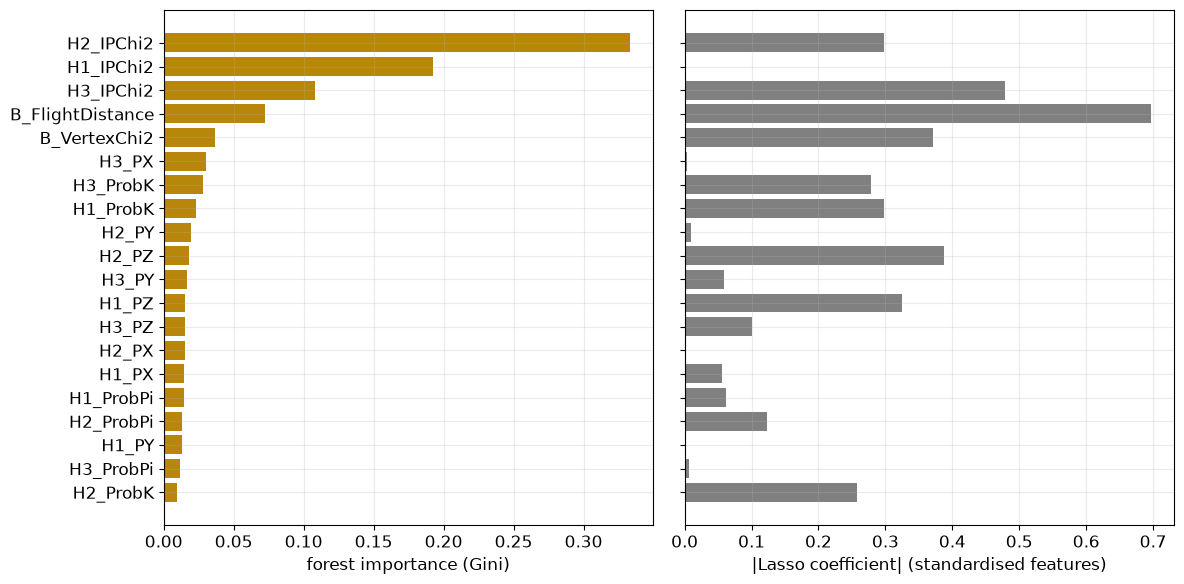

In [11]:
# importance of the 20 features by the forest (Gini) and by the Lasso (|coefficient|): table and figure
tab_feat = pd.DataFrame({"feature": FEATURES, "rf_importance": imp, "abs_lasso_coef": coef}).sort_values("rf_importance", ascending=False)
tab_feat.to_csv("results/08_feature_importance.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
yy = np.arange(len(tab_feat))[::-1]
ax[0].barh(yy, tab_feat.rf_importance, color=C["ml"]); ax[0].set(xlabel="forest importance (Gini)")
ax[1].barh(yy, tab_feat.abs_lasso_coef, color="gray"); ax[1].set(xlabel="|Lasso coefficient| (standardised features)")
ax[0].set_yticks(yy); ax[0].set_yticklabels(tab_feat.feature)
plt.tight_layout(); save_fig("08_feature_importance")

## 3 · Regularisation, bias–variance and calibration

**Ridge and Lasso.** The strength $C=1/\alpha$ of the penalty of the logistic regression is scanned on a logarithmic
grid and chosen on the cross-validated AUC. If the AUC is flat over a wide range the model is not limited by variance
but by the form of its decision boundary (a *linear* boundary).

best L1: C = 0.139, AUC = 0.7804;  best L2: C = 100, AUC = 0.7802   (report: both 0.7686)


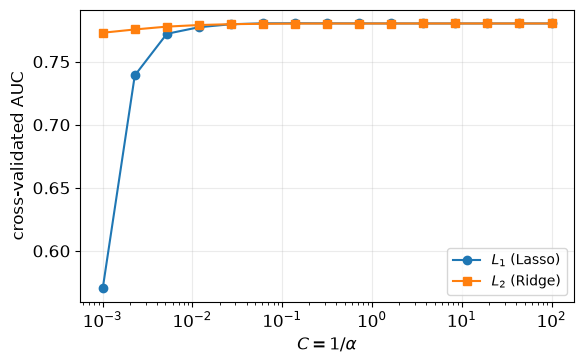

In [12]:
C_grid = np.logspace(-3, 2, 15)          # C = 1/alpha: small C = strong regularisation
# cross-validated AUC against the regularisation strength, for the Lasso (L1) and the Ridge (L2) penalty
auc_l1 = [cross_val_score(LogisticRegression(penalty="l1", solver="liblinear", C=c, class_weight="balanced", max_iter=2000),
                          Xs_train, y_train, cv=cv, scoring="roc_auc").mean() for c in C_grid]
auc_l2 = [cross_val_score(LogisticRegression(penalty="l2", C=c, class_weight="balanced", max_iter=2000),
                          Xs_train, y_train, cv=cv, scoring="roc_auc").mean() for c in C_grid]
print(f"best L1: C = {C_grid[np.argmax(auc_l1)]:.3g}, AUC = {max(auc_l1):.4f};  best L2: C = {C_grid[np.argmax(auc_l2)]:.3g}, "
      f"AUC = {max(auc_l2):.4f}   (report: both 0.7686)")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(C_grid, auc_l1, "o-", label="$L_1$ (Lasso)"); ax.plot(C_grid, auc_l2, "s-", label="$L_2$ (Ridge)")
ax.set(xscale="log", xlabel="$C=1/\\alpha$", ylabel="cross-validated AUC"); ax.legend()
plt.tight_layout(); save_fig("08_regularization")
pd.DataFrame({"C": C_grid, "auc_l1": auc_l1, "auc_l2": auc_l2}).to_csv("results/08_regularization_scan.csv", index=False)

**Reading the result.** The AUC is flat over a wide range of $C$ and the Lasso and the Ridge reach the same maximum: the logistic regression is not limited by variance (no overfitting to cure by regularising) but by its linear decision boundary.

**Bias–variance.** The complexity of gradient boosting grows with the number of stages. Evaluating the model after
each stage on the training and on the test set, a growing gap between the two curves is **variance** (overfitting);
a common plateau at a low value is **bias**.

train-test AUC gap: 0.017 at 20 stages, 0.082 at 300   (report: 0.018 and 0.084)
test AUC at 150 stages 0.8717, at 300 stages 0.8703   (report: plateau 0.865 beyond ~150 stages)


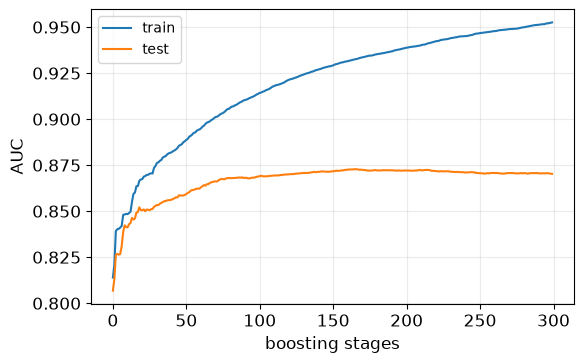

In [13]:
gbm = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm.fit(X_train, y_train, sample_weight=sw_train)
# AUC after each boosting stage (complexity grows with the number of stages), on training and test sets
auc_tr = [roc_auc_score(y_train, p[:, 1]) for p in gbm.staged_predict_proba(X_train)]
auc_te = [roc_auc_score(y_test, p[:, 1]) for p in gbm.staged_predict_proba(X_test)]
print(f"train-test AUC gap: {auc_tr[19] - auc_te[19]:.3f} at 20 stages, {auc_tr[-1] - auc_te[-1]:.3f} at 300   (report: 0.018 and 0.084)")
print(f"test AUC at 150 stages {auc_te[149]:.4f}, at 300 stages {auc_te[-1]:.4f}   (report: plateau 0.865 beyond ~150 stages)")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(auc_tr, label="train"); ax.plot(auc_te, label="test"); ax.set(xlabel="boosting stages", ylabel="AUC"); ax.legend()
plt.tight_layout(); save_fig("08_bias_variance")
pd.DataFrame({"stage": np.arange(1, len(auc_tr) + 1), "auc_train": auc_tr, "auc_test": auc_te}).to_csv("results/08_boosting_stages.csv", index=False)

**Reading the result.** The training AUC keeps growing with the number of stages while the test AUC saturates: the gap between the two is variance (overfitting). Beyond $\sim150$ stages the extra complexity brings nothing on the test set.

**Calibration** [EXTRA]. A score is a probability only if among the candidates with score $\approx p$ a fraction $p$
is signal-like. Class weights *bias* the probabilities: they converge to $\tilde p=w_sp/[w_sp+w_b(1-p)]$ instead of
$p$. An isotonic recalibration on held-out folds corrects it without changing the ranking (so the AUC does not
change). We measure it with the Brier score $\langle(s-y)^2\rangle$.

Brier score of the forest: raw 0.120 -> isotonic 0.061   (report: 0.122 -> 0.062)
AUC raw 0.8660, recalibrated 0.8632


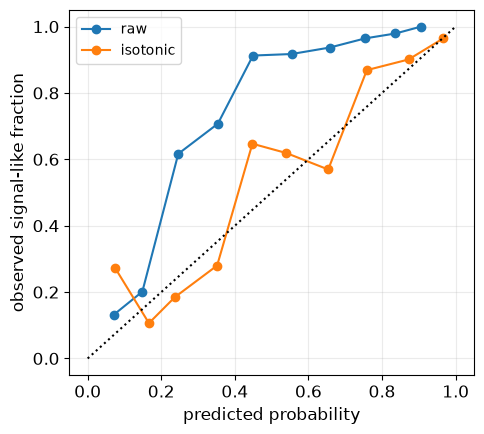

In [14]:
rf_raw = scores["Random Forest"]                                       # raw scores of the forest on the test set
# isotonic recalibration: a monotonic map score -> probability learned on held-out folds (ranking unchanged)
cal = CalibratedClassifierCV(RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20,
                             class_weight="balanced", random_state=SEED, n_jobs=-1), method="isotonic", cv=5).fit(X_train, y_train)
rf_cal = cal.predict_proba(X_test)[:, 1]
print(f"Brier score of the forest: raw {brier_score_loss(y_test, rf_raw):.3f} -> isotonic {brier_score_loss(y_test, rf_cal):.3f}   (report: 0.122 -> 0.062)")
print(f"AUC raw {roc_auc_score(y_test, rf_raw):.4f}, recalibrated {roc_auc_score(y_test, rf_cal):.4f}")
# reliability diagram: observed fraction of signal-like candidates against the predicted probability
fig, ax = plt.subplots(figsize=(5, 4.5))
for s_, lab in ((rf_raw, "raw"), (rf_cal, "isotonic")):
    obs, pred = calibration_curve(y_test, s_, n_bins=10)
    ax.plot(pred, obs, "o-", label=lab)
ax.plot([0, 1], [0, 1], "k:"); ax.set(xlabel="predicted probability", ylabel="observed signal-like fraction"); ax.legend()
plt.tight_layout(); save_fig("08_calibration")
np.savez("results/08_calibration.npz", y_test=y_test, rf_raw=rf_raw, rf_isotonic=rf_cal)

## 4 · Uncertainty of the score

A classifier output comes with an uncertainty. Three estimators, on the test set:

* **Random forest**: standard deviation of the predictions of the individual trees;
* **MC dropout**: the FFNN with dropout *kept active* at prediction time, many stochastic forward passes;
* **deep ensemble**: several FFNNs trained from different random seeds.

They measure different sources of variability. The dependence of the forest spread on the size of the training set
(25 %, 50 %, 100 %) separates the *epistemic* part, which shrinks with more data, from the *aleatoric* part (the
irreducible overlap of the two classes, largest for scores around 0.5).

*Report:* 300 trees, 300 passes, 10 networks. Here 100 passes and 5 networks.

mean per-candidate uncertainty: forest 0.181, MC dropout 0.094, deep ensemble 0.042   (report: 0.178, 0.095, 0.050)
Spearman correlations: forest-MC dropout 0.55, forest-ensemble 0.36, MC dropout-ensemble 0.44


  forest spread with  25% of the training set: 0.221   (report: 0.220, 0.204, 0.179)


  forest spread with  50% of the training set: 0.201   (report: 0.220, 0.204, 0.179)


  forest spread with 100% of the training set: 0.181   (report: 0.220, 0.204, 0.179)


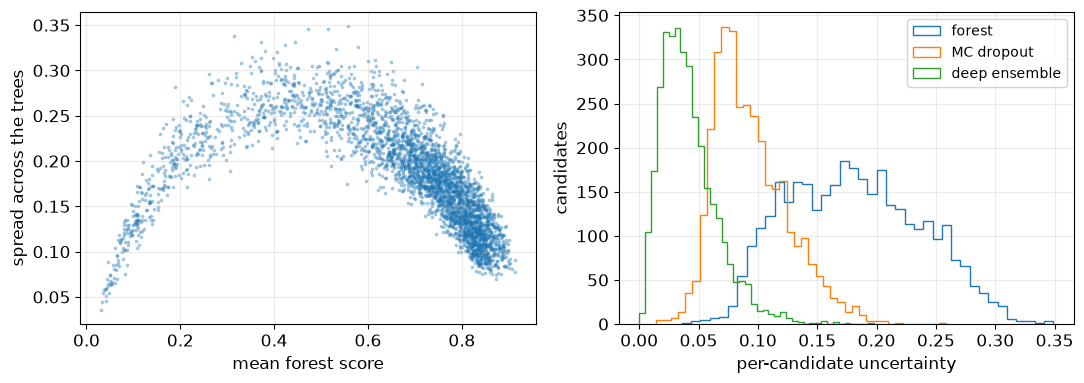

In [15]:
# (1) random forest: spread of the predictions of the individual trees, for each test candidate
rf = fitted["Random Forest"][0]
tree_preds = np.stack([t.predict_proba(X_test)[:, 1] for t in rf.estimators_])      # shape (trees, candidates)
unc_rf = tree_preds.std(axis=0)

# (2) MC dropout: the FFNN with dropout active at prediction time, 100 stochastic forward passes
xt = tf.constant(Xs_test, dtype=tf.float32)
mc = np.stack([ffnn(xt, training=True).numpy().ravel() for _ in range(100)])        # training=True keeps dropout on
unc_mc = mc.std(axis=0)

# (3) deep ensemble: 5 networks trained from different random seeds
nets = [ffnn] + [train_ffnn(Xs_train, y_train, Xs_val, y_val, seed=s) for s in range(1, 5)]
unc_de = np.stack([n.predict(Xs_test, verbose=0).ravel() for n in nets]).std(axis=0)

print(f"mean per-candidate uncertainty: forest {unc_rf.mean():.3f}, MC dropout {unc_mc.mean():.3f}, deep ensemble {unc_de.mean():.3f}"
      "   (report: 0.178, 0.095, 0.050)")
print("Spearman correlations: forest-MC dropout {:.2f}, forest-ensemble {:.2f}, MC dropout-ensemble {:.2f}".format(
    spearmanr(unc_rf, unc_mc).correlation, spearmanr(unc_rf, unc_de).correlation, spearmanr(unc_mc, unc_de).correlation))

# epistemic uncertainty shrinks with more training data: forest spread with 25 %, 50 % and 100 % of the training set
for frac in (0.25, 0.5, 1.0):
    idx = np.random.choice(len(y_train), int(frac * len(y_train)), replace=False)
    r_ = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                random_state=SEED, n_jobs=-1).fit(X_train[idx], y_train[idx])
    sp = np.stack([t.predict_proba(X_test)[:, 1] for t in r_.estimators_]).std(axis=0)
    print(f"  forest spread with {int(100 * frac):3d}% of the training set: {sp.mean():.3f}   (report: 0.220, 0.204, 0.179)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mean_score = tree_preds.mean(axis=0)
ax[0].scatter(mean_score, unc_rf, s=3, alpha=0.3); ax[0].set(xlabel="mean forest score", ylabel="spread across the trees")
for u, lab in ((unc_rf, "forest"), (unc_mc, "MC dropout"), (unc_de, "deep ensemble")):
    ax[1].hist(u, bins=40, histtype="step", label=lab)
ax[1].set(xlabel="per-candidate uncertainty", ylabel="candidates"); ax[1].legend()
plt.tight_layout(); save_fig("08_uncertainty")
np.savez("results/08_uncertainty.npz", mean_forest_score=mean_score, forest=unc_rf, mc_dropout=unc_mc, deep_ensemble=unc_de)

**Reading the result.** The three estimators measure different things (variability across trees, across dropout masks, across trainings), so their absolute values differ. Only the forest spread decreases visibly with the training-set size (the epistemic part); what remains for scores around $0.5$ is the aleatoric part, the overlap of the two classes.

## 5 · Hyperparameter search and the winner's curse [EXTRA]

Do better hyperparameters help? We scan small grids with cross-validation and compare the *test* AUC of the best
configuration with that of the default. Two warnings: the cross-validated maximum is an *optimistic* estimate of the
performance (the *winner's curse*: the best of many noisy values is biased upward), and the gain must be compared
with the uncertainty of the test AUC ($\approx0.012$ here).

*Report:* 120 + 100 + 168 configurations, 5-fold CV repeated 10 times. Here 12 + 12 and 3-fold.

In [16]:
# exhaustive grid search with 3-fold cross-validation, scored on the AUC
gs_rf = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                     {"n_estimators": [100, 300], "max_depth": [4, 8, None], "min_samples_leaf": [5, 20]},
                     cv=3, scoring="roc_auc").fit(X_train, y_train)
gs_gb = GridSearchCV(GradientBoostingClassifier(random_state=SEED),
                     {"n_estimators": [100, 200], "max_depth": [2, 3, 4], "learning_rate": [0.05, 0.1]},
                     cv=3, scoring="roc_auc").fit(X_train, y_train, sample_weight=sw_train)
for lab, gs, default in (("Random Forest", gs_rf, "Random Forest"), ("Gradient Boosting", gs_gb, "Gradient Boosting")):
    t_best = roc_auc_score(y_test, gs.best_estimator_.predict_proba(X_test)[:, 1])    # test AUC of the best configuration
    t_def = roc_auc_score(y_test, scores[default])                                    # and of the default one
    # winner's curse: the cross-validated maximum is an optimistic estimate of the test performance
    print(f"{lab:18s} best {gs.best_params_}\n   CV AUC of the best = {gs.best_score_:.4f}, test AUC = {t_best:.4f} (default: {t_def:.4f}); "
          f"winner's curse = CV - test = {gs.best_score_ - t_best:+.4f}")
print("report: the best configurations gain at most 0.005 in AUC, less than the test uncertainty (0.012)")

# FFNN: a few architectures x dropout rates, 3-fold cross-validation (the report scans 168 configurations)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
ffnn_res = []
for layers in ((16,), (32, 16), (64, 32, 16)):
    for dropout in (0.1, 0.3):
        aucs = []
        for tr, te in cv3.split(Xs_train, y_train):
            net = train_ffnn(Xs_train[tr], y_train[tr], Xs_train[te], y_train[te], layers=layers, dropout=dropout)
            aucs.append(roc_auc_score(y_train[te], net.predict(Xs_train[te], verbose=0).ravel()))
        ffnn_res.append((layers, dropout, np.mean(aucs), np.std(aucs)))
ffnn_res = pd.DataFrame(ffnn_res, columns=["layers", "dropout", "cv_auc", "fold_sd"]).sort_values("cv_auc", ascending=False)
print(ffnn_res.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("report (168 configurations): the top five are within 0.0007 of each other, far below the fold-to-fold spread: a plateau")

Random Forest      best {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
   CV AUC of the best = 0.8727, test AUC = 0.8647 (default: 0.8660); winner's curse = CV - test = +0.0080
Gradient Boosting  best {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
   CV AUC of the best = 0.8703, test AUC = 0.8721 (default: 0.8721); winner's curse = CV - test = -0.0018
report: the best configurations gain at most 0.005 in AUC, less than the test uncertainty (0.012)


      layers  dropout  cv_auc  fold_sd
(64, 32, 16)   0.3000  0.8576   0.0121
(64, 32, 16)   0.1000  0.8571   0.0100
    (32, 16)   0.1000  0.8518   0.0113
    (32, 16)   0.3000  0.8499   0.0123
       (16,)   0.1000  0.8361   0.0066
       (16,)   0.3000  0.8306   0.0066
report (168 configurations): the top five are within 0.0007 of each other, far below the fold-to-fold spread: a plateau


**Reading the result.** The best configuration gains little or nothing on the test set, and its cross-validated AUC is optimistic compared with the test AUC (winner's curse): the default hyperparameters are adequate.

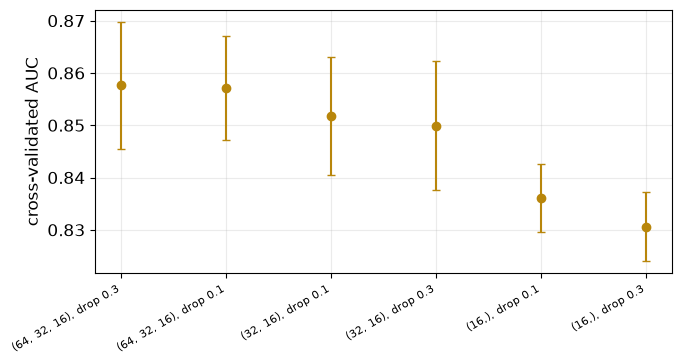

In [17]:
# all the configurations of the grid searches, saved, and the FFNN scan drawn
pd.DataFrame(gs_rf.cv_results_).to_csv("results/08_grid_search_forest.csv", index=False)
pd.DataFrame(gs_gb.cv_results_).to_csv("results/08_grid_search_boosting.csv", index=False)
ffnn_res.to_csv("results/08_ffnn_search.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
lab_f = [f"{l}, drop {d}" for l, d in zip(ffnn_res.layers, ffnn_res.dropout)]
ax.errorbar(range(len(ffnn_res)), ffnn_res.cv_auc, ffnn_res.fold_sd, fmt="o", color=C["ml"], capsize=3)
ax.set_xticks(range(len(ffnn_res))); ax.set_xticklabels(lab_f, rotation=30, ha="right", fontsize=8); ax.set(ylabel="cross-validated AUC")
plt.tight_layout(); save_fig("08_ffnn_search")

## Results saved

In [18]:
summary = dict(
    labels=dict(mu=float(MU), sigma=float(SIGMA), n_signal_like=int(labeled.y.sum()), n_background_like=int((labeled.y == 0).sum())),
    cv_auc={n: [float(v[0]), float(v[1])] for n, v in cv_auc.items()},
    test_auc={n: float(roc_auc_score(y_test, scores[n])) for n in order},
    uncertainty=dict(forest=float(unc_rf.mean()), mc_dropout=float(unc_mc.mean()), deep_ensemble=float(unc_de.mean())))
json.dump(summary, open("results/08_summary.json", "w"), indent=1)
ffnn_res.to_csv("results/08_ffnn_search.csv", index=False)
print("saved results/08_summary.json; figures in figures/")

saved results/08_summary.json; figures in figures/


## Summary
* Weak labels from the mass (CWoLa) give a signal/background classifier without true labels, provided the mass is not a
  feature; classes are imbalanced and are balanced with class weights.
* Tree ensembles and the FFNN are indistinguishable (test AUC $\approx0.86$) and $\approx0.09$ above the linear models;
  Ridge and Lasso reach the same AUC (the limit is the linear boundary, not the variance); gradient boosting overfits
  beyond ~150 stages without gain.
* Class weights bias the probabilities and an isotonic recalibration corrects them; the three uncertainty estimators
  measure different sources of variability; the hyperparameter search gains nothing significant (winner's curse).

In [19]:
print(f"Running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Running time of this notebook: 9.2 min
